<a href="https://colab.research.google.com/github/vsai4607/MLA0204/blob/main/program20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving Future_Sales_Dataset.xlsx to Future_Sales_Dataset.xlsx
Dataset Loaded Successfully!
        Date  Month  Year  Sales
0 2023-01-01      1  2023    823
1 2023-02-01      2  2023   1008
2 2023-03-01      3  2023    880
3 2023-04-01      4  2023   1150
4 2023-05-01      5  2023   1033

Mean Absolute Error: 129.87017970351306
R2 Score: 0.5804562044683779

Future Sales Prediction:
January 2026 : 1476.69
February 2026 : 1493.79
March 2026 : 1510.88
April 2026 : 1527.97
May 2026 : 1545.07
June 2026 : 1562.16


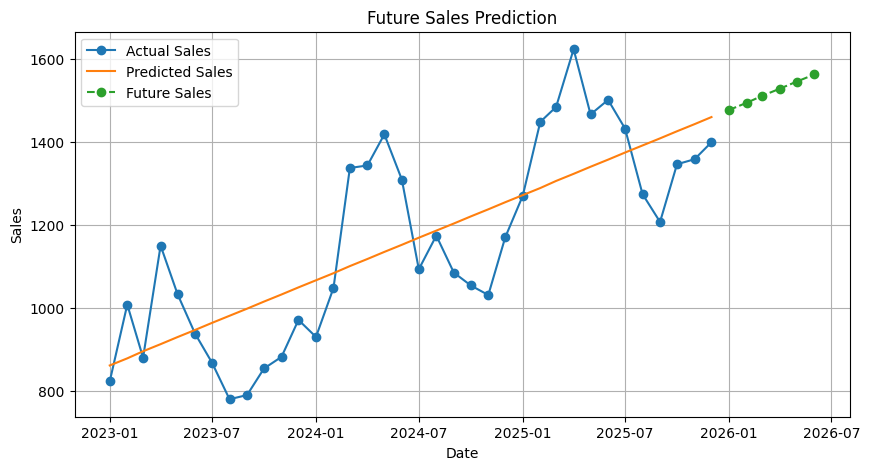

In [2]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# Upload Excel dataset
uploaded = files.upload()

# Read Excel file
df = pd.read_excel(list(uploaded.keys())[0])

print("Dataset Loaded Successfully!")
print(df.head())

# Convert date column
df['Date'] = pd.to_datetime(df['Date'])

# Create input and output
X = np.arange(len(df)).reshape(-1, 1)
y = df['Sales']

# Train Linear Regression model
model = LinearRegression()
model.fit(X, y)

# Predict existing sales
y_pred = model.predict(X)

# Calculate accuracy metrics
print("\nMean Absolute Error:",
      mean_absolute_error(y, y_pred))

print("R2 Score:", r2_score(y, y_pred))

# Predict next 6 months
future_X = np.arange(len(df), len(df) + 6).reshape(-1, 1)
future_sales = model.predict(future_X)

# Display future predictions
future_dates = pd.date_range(
    start=df['Date'].iloc[-1] + pd.DateOffset(months=1),
    periods=6,
    freq='MS'
)

print("\nFuture Sales Prediction:")
for date, sale in zip(future_dates, future_sales):
    print(date.strftime('%B %Y'), ":", round(sale, 2))

# Plot graph
plt.figure(figsize=(10, 5))
plt.plot(df['Date'], y, label='Actual Sales', marker='o')
plt.plot(df['Date'], y_pred, label='Predicted Sales')
plt.plot(future_dates, future_sales,
         label='Future Sales', marker='o', linestyle='--')

plt.xlabel("Date")
plt.ylabel("Sales")
plt.title("Future Sales Prediction")
plt.legend()
plt.grid()
plt.show()